In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['figure.figsize'] = (8, 5)
sns.set_style('whitegrid')

cust = pd.read_csv('FinTrust_Customer_Data - FinTrust_Customer_Data.csv')
tx = pd.read_csv('FinTrust_Transaction_Data - FinTrust_Transaction_Data.csv')

try:
    tx['Transaction_DateTime'] = pd.to_datetime(tx['Transaction_DateTime'], format='%m/%d/%Y %H:%M')
except ValueError:
    tx['Transaction_DateTime'] = pd.to_datetime(tx['Transaction_DateTime'], format='ISO8601')

tx['Device_Type'] = tx['Device_Type'].fillna('Unknown')
tx['Location'] = tx['Location'].fillna('Unknown')

tx['flag'] = (tx['Risk_Review_Flag'] == 'Yes').astype(int)
tx['failed'] = (tx['Transaction_Status'] == 'Failed').astype(int)
tx = tx.merge(cust[['Customer_ID', 'Customer_Segment']], on='Customer_ID', how='left')

print('Customers:', cust.shape, '| Transactions:', tx.shape)

Customers: (1500, 12) | Transactions: (12000, 14)


In [4]:
checks = {
    'Customer rows (expect 1500)': len(cust),
    'Transaction rows (expect 12000)': len(tx),
    'Duplicate Transaction_ID (expect 0)': int(tx['Transaction_ID'].duplicated().sum()),
    'Duplicate Customer_ID (expect 0)': int(cust['Customer_ID'].duplicated().sum()),
    'Missing values, customers (expect 0)': int(cust.isnull().sum().sum()),
    'Missing values, transactions (expect 0)': int(tx.isnull().sum().sum()),
    'Orphaned transactions (expect 0)': len(set(tx['Customer_ID']) - set(cust['Customer_ID'])),
    'Customers with no transactions (expect 0)': len(set(cust['Customer_ID']) - set(tx['Customer_ID'])),
    'Unparseable dates (expect 0)': int(tx['Transaction_DateTime'].isnull().sum()),
    'Negative or zero amounts (expect 0)': int((tx['Amount_NGN'] <= 0).sum()),
    "Device_Type 'Unknown' (expect 96)": int((tx['Device_Type'] == 'Unknown').sum()),
    "Location 'Unknown' (expect 96)": int((tx['Location'] == 'Unknown').sum()),
}
for k, v in checks.items():
    print(f'{k:45s} {v}')
print('\nDate range:', tx['Transaction_DateTime'].min(), 'to', tx['Transaction_DateTime'].max())

Customer rows (expect 1500)                   1500
Transaction rows (expect 12000)               12000
Duplicate Transaction_ID (expect 0)           0
Duplicate Customer_ID (expect 0)              0
Missing values, customers (expect 0)          0
Missing values, transactions (expect 0)       0
Orphaned transactions (expect 0)              0
Customers with no transactions (expect 0)     0
Unparseable dates (expect 0)                  0
Negative or zero amounts (expect 0)           0
Device_Type 'Unknown' (expect 96)             96
Location 'Unknown' (expect 96)                96

Date range: 2026-01-01 00:00:00 to 2026-03-31 23:59:00


In [5]:
print(pd.crosstab(tx['Channel'], tx['Device_Type']))

Device_Type  ATM Terminal  Android  POS Terminal  Unknown  Web Browser   iOS
Channel                                                                     
ATM                   176      660           234       11          219   447
Mobile App            524     2059           618       42          608  1251
POS                   210      968           324       23          298   570
USSD                   87      374           123        6          109   190
Web                   172      736           272       14          213   462


In [6]:
kpis = {
    'Total Customers':           (cust['Customer_ID'].nunique(), 1500),
    'Total Transactions':        (len(tx), 12000),
    'Total Transaction Value':   (round(tx['Amount_NGN'].sum(), 2), 560477354.85),
    'Average Transaction Value': (round(tx['Amount_NGN'].mean(), 2), 46706.45),
    'Success Rate (%)':          (round((tx['Transaction_Status'] == 'Successful').mean() * 100, 2), 90.47),
    'Risk Review Rate (%)':      (round(tx['flag'].mean() * 100, 2), 19.60),
    'Failure Rate (%)':          (round(tx['failed'].mean() * 100, 2), 5.25),
    'Active Customer Rate (%)':  (round((cust['Account_Status'] == 'Active').mean() * 100, 2), 91.13),
}
for name, (calc, expected) in kpis.items():
    status = 'PASS' if abs(calc - expected) < 0.01 else 'CHECK'
    print(f'{name:28s} calculated {calc:>18,.2f}   dashboard {expected:>18,.2f}   {status}')

Total Customers              calculated           1,500.00   dashboard           1,500.00   PASS
Total Transactions           calculated          12,000.00   dashboard          12,000.00   PASS
Total Transaction Value      calculated     560,477,354.85   dashboard     560,477,354.85   PASS
Average Transaction Value    calculated          46,706.45   dashboard          46,706.45   PASS
Success Rate (%)             calculated              90.47   dashboard              90.47   PASS
Risk Review Rate (%)         calculated              19.60   dashboard              19.60   PASS
Failure Rate (%)             calculated               5.25   dashboard               5.25   PASS
Active Customer Rate (%)     calculated              91.13   dashboard              91.13   PASS


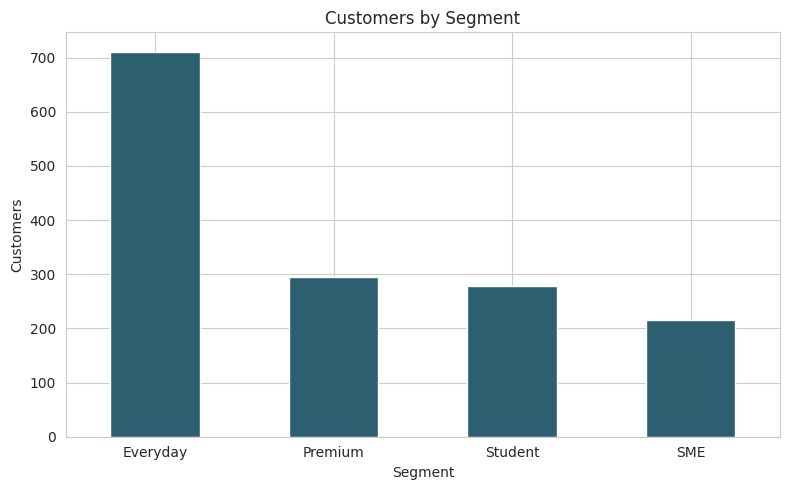

In [7]:
cust['Customer_Segment'].value_counts().plot(kind='bar', color='#2C5F6F')
plt.title('Customers by Segment'); plt.xlabel('Segment'); plt.ylabel('Customers'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

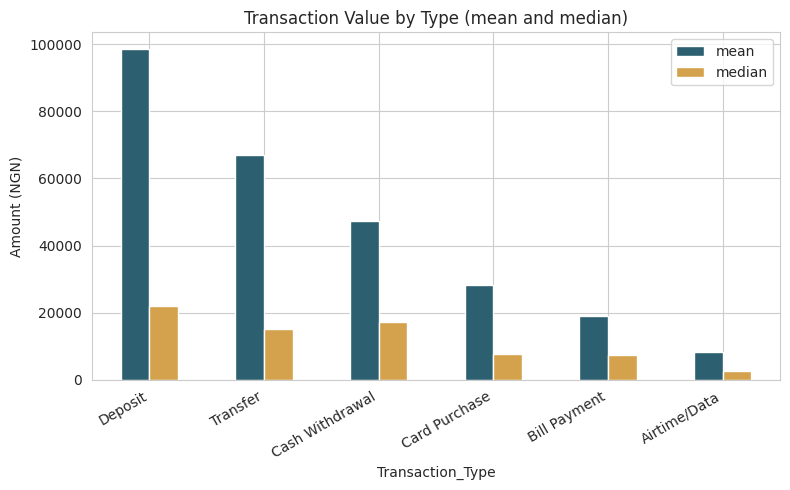

                     mean   median
Transaction_Type                  
Deposit           98633.0  22094.0
Transfer          67038.0  15082.0
Cash Withdrawal   47393.0  17357.0
Card Purchase     28310.0   7629.0
Bill Payment      19094.0   7403.0
Airtime/Data       8250.0   2494.0


In [8]:
summary = tx.groupby('Transaction_Type')['Amount_NGN'].agg(['mean', 'median']).sort_values('mean', ascending=False)
summary.plot(kind='bar', color=['#2C5F6F', '#D4A24C'])
plt.title('Transaction Value by Type (mean and median)'); plt.ylabel('Amount (NGN)'); plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.show()
print(summary.round(0))

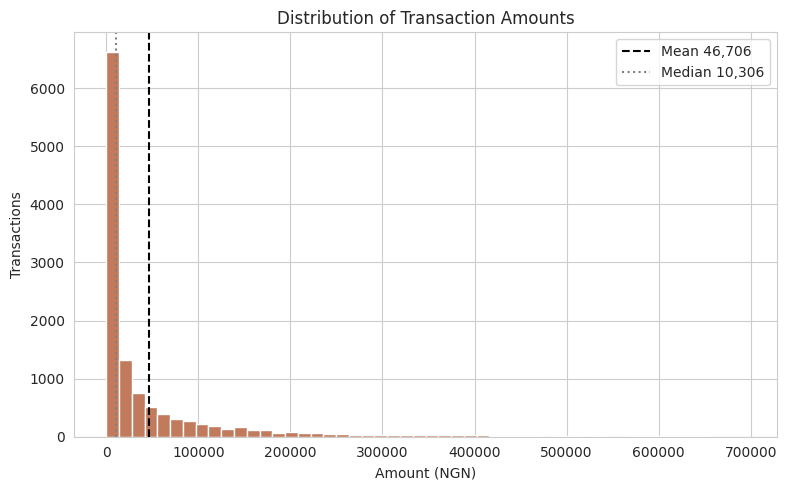

In [9]:
plt.hist(tx['Amount_NGN'], bins=50, color='#C17B5C')
plt.axvline(tx['Amount_NGN'].mean(), color='black', linestyle='--', label=f"Mean {tx['Amount_NGN'].mean():,.0f}")
plt.axvline(tx['Amount_NGN'].median(), color='grey', linestyle=':', label=f"Median {tx['Amount_NGN'].median():,.0f}")
plt.title('Distribution of Transaction Amounts'); plt.xlabel('Amount (NGN)'); plt.ylabel('Transactions'); plt.legend()
plt.tight_layout(); plt.show()

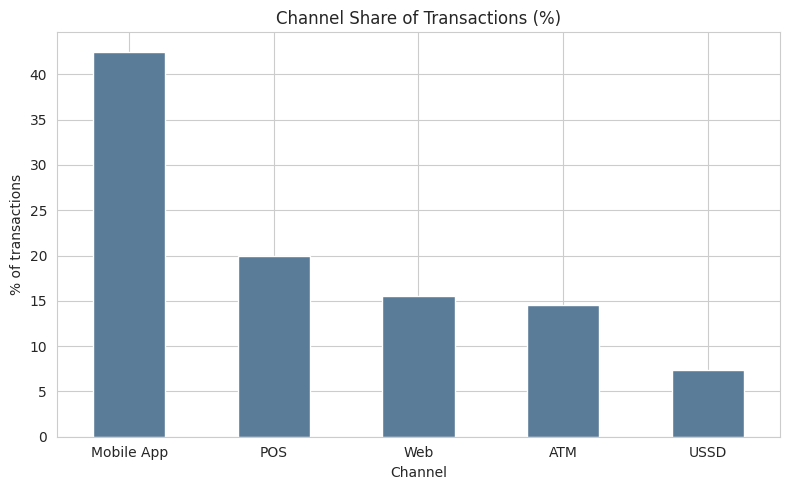

In [10]:
(tx['Channel'].value_counts(normalize=True) * 100).plot(kind='bar', color='#5B7C99')
plt.title('Channel Share of Transactions (%)'); plt.ylabel('% of transactions'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

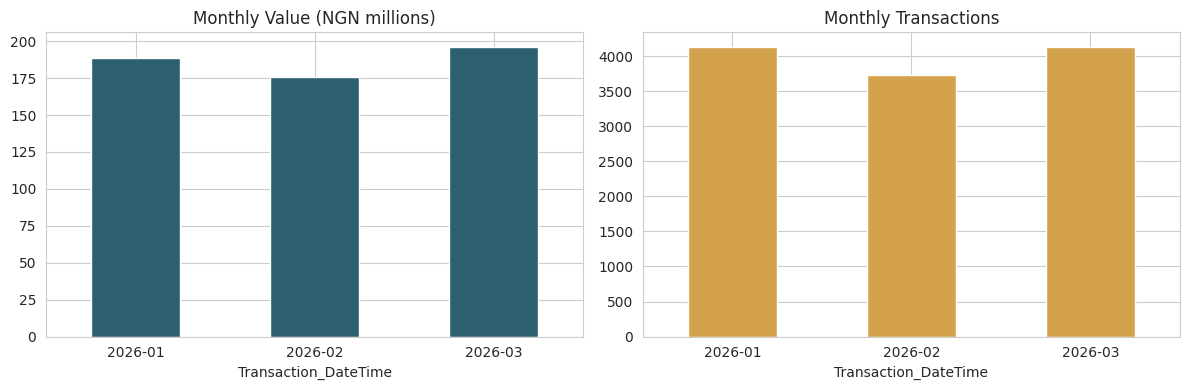

                             value  count
Transaction_DateTime                     
2026-01               1.884894e+08   4133
2026-02               1.757869e+08   3734
2026-03               1.962010e+08   4133


In [11]:
monthly = tx.groupby(tx['Transaction_DateTime'].dt.to_period('M')).agg(value=('Amount_NGN', 'sum'), count=('Amount_NGN', 'size'))
monthly.index = monthly.index.astype(str)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
monthly['value'].div(1e6).plot(kind='bar', ax=ax[0], color='#2C5F6F'); ax[0].set_title('Monthly Value (NGN millions)'); ax[0].tick_params(axis='x', rotation=0)
monthly['count'].plot(kind='bar', ax=ax[1], color='#D4A24C'); ax[1].set_title('Monthly Transactions'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print(monthly.round(2))

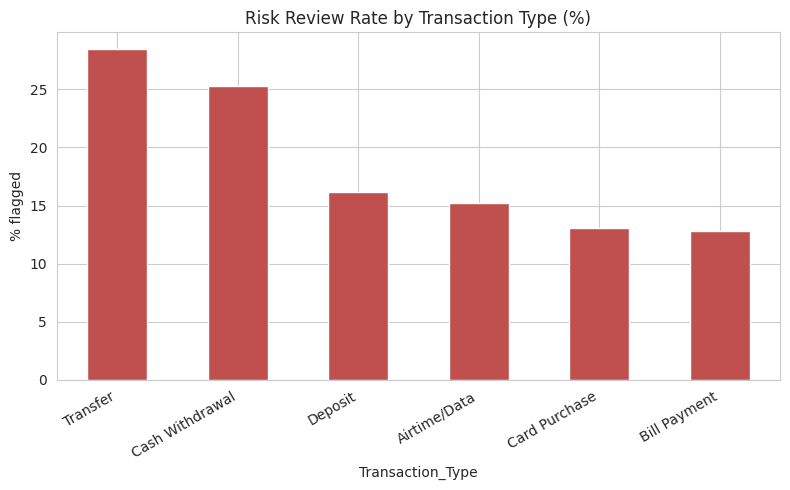

In [12]:
(tx.groupby('Transaction_Type')['flag'].mean() * 100).sort_values(ascending=False).plot(kind='bar', color='#C0504D')
plt.title('Risk Review Rate by Transaction Type (%)'); plt.ylabel('% flagged'); plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.show()

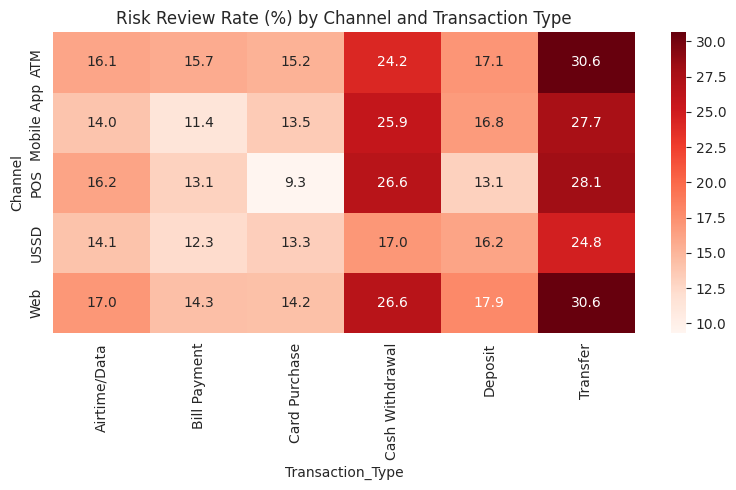

In [13]:
heat = tx.pivot_table(index='Channel', columns='Transaction_Type', values='flag', aggfunc='mean') * 100
sns.heatmap(heat, annot=True, fmt='.1f', cmap='Reds')
plt.title('Risk Review Rate (%) by Channel and Transaction Type')
plt.tight_layout(); plt.show()

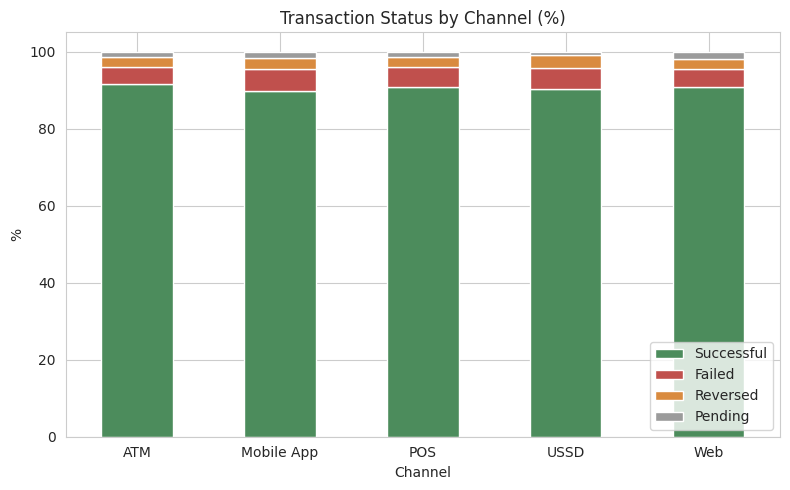

In [14]:
status = pd.crosstab(tx['Channel'], tx['Transaction_Status'], normalize='index') * 100
status[['Successful', 'Failed', 'Reversed', 'Pending']].plot(kind='bar', stacked=True, color=['#4C8C5C', '#C0504D', '#D98B3F', '#9B9B9B'])
plt.title('Transaction Status by Channel (%)'); plt.ylabel('%'); plt.xticks(rotation=0); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

In [15]:
def chi_p(a, b):
    return stats.chi2_contingency(pd.crosstab(a, b))[1]

print('VALIDATION 1: RISK FLAG DRIVERS (chi-square p-values)')
print('  Transaction type:', f"{chi_p(tx['Transaction_Type'], tx['flag']):.2e}")
print('  Channel:         ', f"{chi_p(tx['Channel'], tx['flag']):.3f}")
print('  Segment:         ', f"{chi_p(tx['Customer_Segment'], tx['flag']):.3f}")
print((tx.groupby('Transaction_Type')['flag'].mean() * 100).round(2).sort_values(ascending=False))
print('CONCLUSION: type is a strong driver, channel is weak, segment has no detectable effect.')

VALIDATION 1: RISK FLAG DRIVERS (chi-square p-values)
  Transaction type: 2.88e-75
  Channel:          0.019
  Segment:          0.751
Transaction_Type
Transfer           28.49
Cash Withdrawal    25.31
Deposit            16.19
Airtime/Data       15.19
Card Purchase      13.02
Bill Payment       12.81
Name: flag, dtype: float64
CONCLUSION: type is a strong driver, channel is weak, segment has no detectable effect.


In [16]:
print('VALIDATION 2: INTERNATIONAL vs DOMESTIC')
print((tx.groupby('International_Transaction')[['flag', 'failed']].mean() * 100).round(2))
print('  Risk p-value:   ', f"{chi_p(tx['International_Transaction'], tx['flag']):.2e}")
print('  Failure p-value:', f"{chi_p(tx['International_Transaction'], tx['failed']):.3f}")
print('\nRisk rate (%) within each transaction type:')
print((tx.groupby(['Transaction_Type', 'International_Transaction'])['flag'].mean() * 100).round(1).unstack())
print('CONCLUSION: the gap appears inside every type, so it is a real international effect.')

VALIDATION 2: INTERNATIONAL vs DOMESTIC
                            flag  failed
International_Transaction               
No                         18.88    5.36
Yes                        36.88    2.50
  Risk p-value:    3.96e-22
  Failure p-value: 0.008

Risk rate (%) within each transaction type:
International_Transaction    No   Yes
Transaction_Type                     
Airtime/Data               14.4  32.0
Bill Payment               12.3  26.8
Card Purchase              12.1  35.2
Cash Withdrawal            24.9  40.5
Deposit                    15.2  38.6
Transfer                   27.9  42.0
CONCLUSION: the gap appears inside every type, so it is a real international effect.


In [17]:
cv = tx.groupby(['Customer_ID', 'Customer_Segment'])['Amount_NGN'].sum().reset_index()
print('VALIDATION 3: VALUE PER CUSTOMER BY SEGMENT')
print(cv.groupby('Customer_Segment')['Amount_NGN'].agg(['mean', 'std', 'count']).round(0))
groups = [g['Amount_NGN'].values for _, g in cv.groupby('Customer_Segment')]
print('  ANOVA p-value:         ', round(stats.f_oneway(*groups)[1], 3))
print('  Kruskal-Wallis p-value:', round(stats.kruskal(*groups)[1], 3))
sme = cv[cv['Customer_Segment'] == 'SME']['Amount_NGN']
evd = cv[cv['Customer_Segment'] == 'Everyday']['Amount_NGN']
print('  SME vs Everyday p-value:', round(stats.ttest_ind(sme, evd, equal_var=False)[1], 3))
print('CONCLUSION: differences are within random variation. SME most valuable per customer is NOT supported.')

VALIDATION 3: VALUE PER CUSTOMER BY SEGMENT
                      mean       std  count
Customer_Segment                           
Everyday          367734.0  281095.0    711
Premium           365258.0  277516.0    295
SME               387923.0  271299.0    216
Student           386604.0  279974.0    278
  ANOVA p-value:          0.625
  Kruskal-Wallis p-value: 0.463
  SME vs Everyday p-value: 0.343
CONCLUSION: differences are within random variation. SME most valuable per customer is NOT supported.


In [18]:
print('VALIDATION 4: REPEAT-FLAGGED CUSTOMERS vs CHANCE')
tx['p_flag'] = tx.groupby(['Transaction_Type', 'International_Transaction'])['flag'].transform('mean')
observed = int((tx.groupby('Customer_ID')['flag'].sum() >= 3).sum())
rng = np.random.default_rng(7)
sims = []
for _ in range(500):
    simulated = (rng.random(len(tx)) < tx['p_flag'].values).astype(int)
    sims.append(int((pd.Series(simulated).groupby(tx['Customer_ID'].values).sum() >= 3).sum()))
print('  Customers with 3+ flags (observed):', observed)
print('  Expected by chance:', round(np.mean(sims), 1), '+/-', round(np.std(sims), 1))
print('  Simulation p-value:', round(float(np.mean(np.array(sims) >= observed)), 2))
print('CONCLUSION: the observed count is what chance alone produces.')

VALIDATION 4: REPEAT-FLAGGED CUSTOMERS vs CHANCE
  Customers with 3+ flags (observed): 317
  Expected by chance: 313.0 +/- 14.3
  Simulation p-value: 0.4
CONCLUSION: the observed count is what chance alone produces.


In [19]:
act = tx.groupby('Customer_ID').agg(n=('Amount_NGN', 'size'), v=('Amount_NGN', 'sum')).reset_index()
act = act.merge(cust[['Customer_ID', 'Digital_Engagement_Score']], on='Customer_ID')
r1, p1 = stats.pearsonr(act['Digital_Engagement_Score'], act['n'])
r2, p2 = stats.pearsonr(act['Digital_Engagement_Score'], act['v'])
print('VALIDATION 5: ENGAGEMENT vs ACTIVITY')
print(f'  vs transaction count: r = {r1:.3f}, p = {p1:.3f}')
print(f'  vs total value:       r = {r2:.3f}, p = {p2:.3f}')
print('CONCLUSION: both correlations are indistinguishable from zero.')

VALIDATION 5: ENGAGEMENT vs ACTIVITY
  vs transaction count: r = 0.038, p = 0.141
  vs total value:       r = 0.024, p = 0.350
CONCLUSION: both correlations are indistinguishable from zero.


In [20]:
print('VALIDATION 6: FAILURE RATE BY CHANNEL')
fr = tx.groupby('Channel')['failed'].agg(['sum', 'size', 'mean'])
fr['mean'] = (fr['mean'] * 100).round(2)
print(fr.sort_values('mean', ascending=False))
print('  All channels compared, p-value:', round(chi_p(tx['Channel'], tx['failed']), 3))
print('  Mobile App share of all failures:', round(tx[tx['Channel'] == 'Mobile App']['failed'].sum() / tx['failed'].sum() * 100, 1), '%')
print('CONCLUSION: channel failure rates are not significantly different.')

VALIDATION 6: FAILURE RATE BY CHANNEL
            sum  size  mean
Channel                    
Mobile App  296  5102  5.80
USSD         48   889  5.40
POS         125  2393  5.22
Web          88  1869  4.71
ATM          73  1747  4.18
  All channels compared, p-value: 0.081
  Mobile App share of all failures: 47.0 %
CONCLUSION: channel failure rates are not significantly different.


In [21]:
print('VALIDATION 7: AMOUNT AND FLAGGING')
print('  Mann-Whitney p-value:',
      f"{stats.mannwhitneyu(tx[tx['flag'] == 1]['Amount_NGN'], tx[tx['flag'] == 0]['Amount_NGN'])[1]:.2e}")
print(tx.groupby('flag')['Amount_NGN'].agg(['mean', 'median']).round(0))
hv = tx[tx['Amount_NGN'] > tx['Amount_NGN'].quantile(0.9)]
print('\nTop 10% by value: threshold', round(tx['Amount_NGN'].quantile(0.9)), '| transactions', len(hv))
print(hv.groupby('Channel')['flag'].agg(['mean', 'count']).round(3).sort_values('mean', ascending=False))
print('  Channel difference among high-value transactions, p-value:', round(chi_p(hv['Channel'], hv['flag']), 3))
print('CONCLUSION: larger transactions are flagged more. ATM is highest but from a small sample.')

VALIDATION 7: AMOUNT AND FLAGGING
  Mann-Whitney p-value: 5.93e-17
         mean   median
flag                  
0     41324.0   9591.0
1     68786.0  13541.0

Top 10% by value: threshold 143012 | transactions 1200
             mean  count
Channel                 
ATM         0.436    179
Web         0.395    190
Mobile App  0.357    515
POS         0.327    214
USSD        0.245    102
  Channel difference among high-value transactions, p-value: 0.015
CONCLUSION: larger transactions are flagged more. ATM is highest but from a small sample.
